# HOMEWORK 12

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW12

In this homework, you are going to use the code from ```TrafficSignsClassification``` notebook and create your own traffic sign classifier.

In [1]:
# # Silent installation or update
#
# import sys
# import apps.main as mn
#
# # Clean cache
# !"{sys.executable}" -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !"{sys.executable}" -m pip install -U "{package_name}" -q
#
# Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-contrib-python",
#     "torch",
#     "keras",
# ]
#
# for package_name in package_array:
#     if not mn.is_package_satisfied(package_name):
#         !"{sys.executable}" -m pip install "{package_name}" -q


In [2]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input images
# hm_version = 12
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone images
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name, ".git", ".idea"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"


### Step 1

Use the data from ```data/subset_homework.pckl``` (or the ```data/subset_homework``` folder) and visualize some examples. How many images are there for each class?

In [3]:
# Load data

import pickle
import numpy as np
from pathlib import Path
import apps.reporter as rpt

# Input data
n_images = 6
file_name = "resources/data/subset_homework.pckl"

# Solution
file_path = Path(file_name)

# Load data
if file_path.exists():
    with open(file_path, "rb") as f:
        data = pickle.load(f)
else:
    raise FileNotFoundError("File doesn't exist!")

if data is None:
    raise ValueError(f'Incorrect input data "{file_name}"!')

# form classes
class_id_0 = 0
class_id_1 = 1

# get data set
images_0 = data["class_id_0"]
images_1 = data["class_id_1"]

# get lengths
len_0 = len(images_0)
len_1 = len(images_1)

# form labels
labels_0 = np.full(len_0, class_id_0)
labels_1 = np.full(len_1, class_id_1)

# analysis image
temp_img = images_0[0]

# preparing set of images for showing
first_images = []
for idx in range(n_images):
    first_images.append((labels_0[idx], images_0[idx]))
    first_images.append((labels_1[idx], images_1[idx]))

rp = rpt.Reporter()
rp.add_item(f"Class {class_id_0} samples count", str(len_0))
rp.add_item(f"Class {class_id_1} samples count", str(len_1))
rp.add_item("Total dataset samples", str(len_0 + len_1))
rp.add_item("Image: (rows, cols, channels)", str(temp_img.shape))

# Print results
rp.print_pd_report("Dataset Summary")


Attribute,Result
Class 0 samples count,2220
Class 1 samples count,2250
Total dataset samples,4470
"Image: (rows, cols, channels)","(28, 28)"


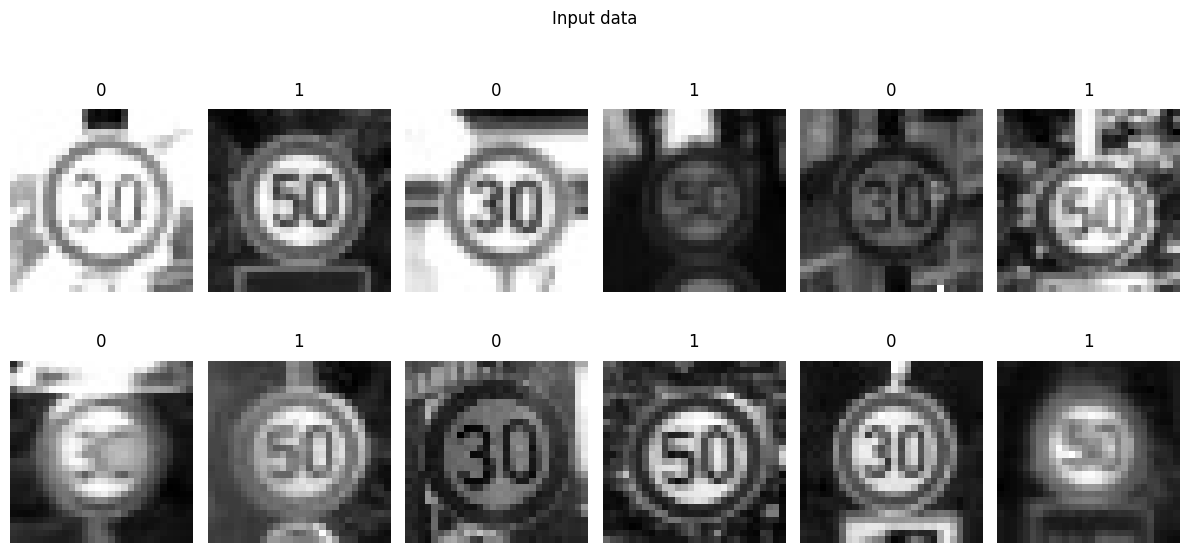

In [4]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = n_images
images_dict = first_images
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data", y=1.0)
plt.tight_layout()
plt.show()


### Step 2

Run the training with one single neuron (as we did in the lecture). What accuracy can you achieve?

Model: "single_linear_neuron"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_pixels (InputLayer)       │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ single_neuron (Dense)           │ (None, 1)              │           785 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 785 (3.07 KB)

 Trainable params: 785 (3.07 KB)

 Non-trainable params: 0 (0.00 B)

Total training:   0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1, Loss: 0.6330, Accuracy: 0.5711, Status: 10.00%
Epoch: 2, Loss: 0.3305, Accuracy: 0.6673, Status: 20.00%
Epoch: 3, Loss: 0.2216, Accuracy: 0.7568, Status: 30.00%
Epoch: 4, Loss: 0.1675, Accuracy: 0.8168, Status: 40.00%
Epoch: 5, Loss: 0.1436, Accuracy: 0.8481, Status: 50.00%
Epoch: 6, Loss: 0.1230, Accuracy: 0.8740, Status: 60.00%
Epoch: 7, Loss: 0.1180, Accuracy: 0.8855, Status: 70.00%
Epoch: 8, Loss: 0.1062, Accuracy: 0.8964, Status: 80.00%
Epoch: 9, Loss: 0.0970, Accuracy: 0.9114, Status: 90.00%
Epoch: 10, Loss: 0.0916, Accuracy: 0.9201, Status: 100.00%


Attribute,Result
Confusion Matrix,[[1972 248] [ 109 2141]]
Accuracy (Точність),0.9201
Precision (Влучність),0.8962
Recall (Повнота),0.9516
F1-score,0.9230
Receiver Operating Characteristic (ROC-AUC),0.9794
Average Precision (AP),0.9805


              precision    recall  f1-score   support

           0       0.95      0.89      0.92      2220
           1       0.90      0.95      0.92      2250

    accuracy                           0.92      4470
   macro avg       0.92      0.92      0.92      4470
weighted avg       0.92      0.92      0.92      4470



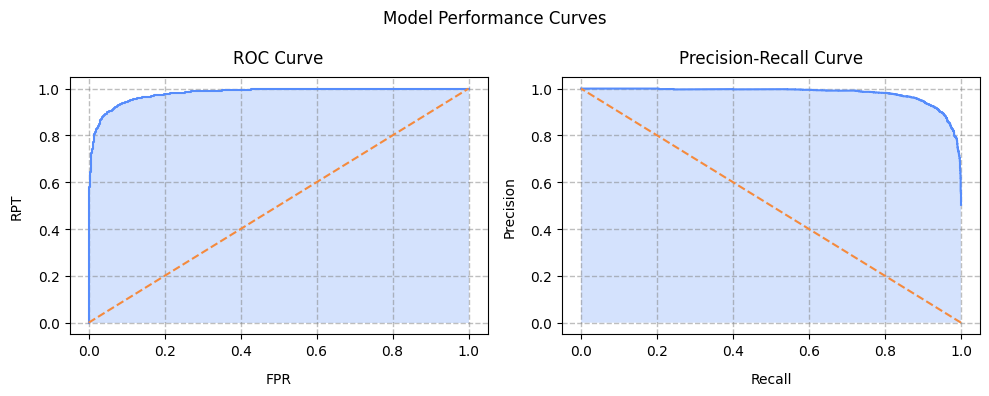

In [41]:
# Single Neuron Training

import numpy as np
import copy
import os

os.environ['KERAS_BACKEND'] = 'torch'

import keras
from keras import Model
from keras.layers import Dense, Input
from sklearn.utils import shuffle
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
import apps.main as mn
import apps.reporter as rpt

# Input data
learning_rate = 0.001
n_epochs = 10
batch_size = 32
# to get similar results every time
rng_seed = 42

# Solution
# merging data
images_01 = np.concatenate([images_0, images_1])
labels_01 = np.concatenate([labels_0, labels_1])
# shuffle
images, labels = shuffle(images_01, labels_01, random_state=rng_seed)
images_flat = np.array(images, dtype=np.float32).reshape(len(images), -1)

# scaling
# (used from https://github.com/BogdanPinchuk/DataScience-PBY_HW18)
scaler = StandardScaler()
pixels = scaler.fit_transform(images_flat)
# for testing/comparing
# pixels = images_flat / 255.0

# set similar behavior for keras
keras.utils.set_random_seed(rng_seed)

# preparing model
inputs = Input(shape=(pixels.shape[1],), name="input_pixels")
outputs = Dense(1, activation="linear", kernel_initializer="glorot_uniform", name="single_neuron")(inputs)
model_single = Model(inputs=inputs, outputs=outputs, name="single_linear_neuron")
# print model
model_single.summary()

# extract init weights
weights_init, bias_init = copy.deepcopy(model_single.layers[1].get_weights())

# compiling
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
# for testing/comparing
# optimizer = keras.optimizers.SGD(learning_rate=learning_rate)
model_single.compile(optimizer=optimizer, loss="mean_squared_error", metrics=["accuracy"])

# training
# for testing/comparing
# history_single = model_single.fit(pixels, labels, epochs=n_epochs, batch_size=batch_size, verbose=2)

losses_single = []
accuracies_single = []

# (used from https://github.com/BogdanPinchuk/DataScience-PBY_HW22)
history_single = None
total_pbar = tqdm(range(n_epochs), desc="Total training", leave=True)
for epoch in total_pbar:
    history_single = model_single.fit(pixels, labels, epochs=1, batch_size=batch_size, verbose=0)
    avg_loss = history_single.history['loss'][-1]
    losses_single.append(avg_loss)
    avg_acc = history_single.history['accuracy'][-1]
    accuracies_single.append(avg_acc)
    # print data in console
    total_pbar.write(
        f"Epoch: {epoch + 1}, Loss: {avg_loss:.4f}, Accuracy: {avg_acc:.4f}, Status: {(epoch + 1.0) / n_epochs:.2%}")

labels_prob = model_single.predict(pixels, verbose=0).squeeze()
labels_pred = (labels_prob >= 0.5).astype(float)

# trained weights
weights_trained, bias_trained = model_single.layers[1].get_weights()
weight_diff = weights_trained - weights_init

images_single = {
    "Initial weights": weights_init.copy().reshape(temp_img.shape),
    "Trained weights": weights_trained.copy().reshape(temp_img.shape),
    "Weight Delta (Trained - Initial)": weight_diff.copy().reshape(temp_img.shape),
}

# Print results
_ = mn.calc_class_metrics(labels, labels_pred, labels_prob)


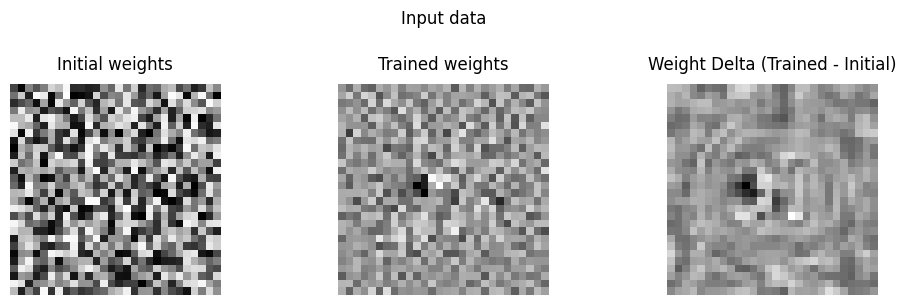

In [42]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 3
images_dict = images_single
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(10, 3 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data", y=1.0)
plt.tight_layout()
plt.show()


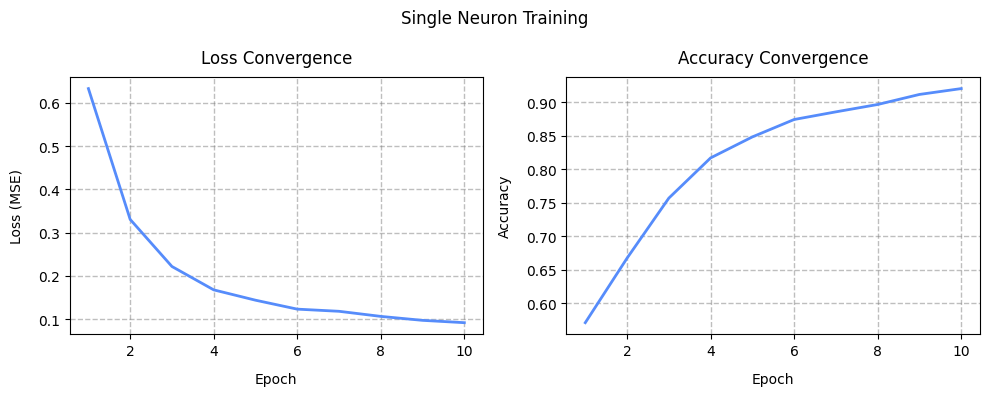

In [49]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
array_x = range(1, n_epochs + 1)
array_y0 = losses_single
array_y1 = accuracies_single

# Solution
_, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(array_x, array_y0, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Loss Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Loss (MSE)", labelpad=10, loc='center', color='black')

ax = axes[1]
ax.plot(array_x, array_y1, linewidth=2.0)
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Accuracy Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epoch", labelpad=10, loc='center', color='black')
ax.set_ylabel("Accuracy", labelpad=10, loc='center', color='black')

plt.suptitle(f"Single Neuron Training")

plt.tight_layout()
plt.show()

### Step 3

Make further modifications to improve the accuracy (e.g. add more neurons, more layers, etc.). What is the maximum accuracy you can achieve?

*Note: the accuracy you compute here is measured on the same images the model was trained on. We will discuss how to evaluate a model properly in one of the next lessons.*

### Bonus question

Stack two ```Dense``` layers with ```activation="linear"``` on top of each other. Do you get a better model than with one single neuron? Why (not)? Hint: have a look at the slide about the neural network and non-linearity.

### Conclusion
1. A